
# Практичне завдання №1
## Лінійна регресія, оптимізація та статистичний аналіз

**Мета роботи:** дослідити архітектуру лінійної регресії, самостійно реалізувати алгоритми градієнтного спуску засобами NumPy, провести відбір ознак, оцінити якість моделі та перевірити статистичні припущення.


In [2]:

# Імпорт необхідних бібліотек

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_regression

from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Налаштування відображення
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

sns.set_theme(style="whitegrid")

# Фіксація випадковості для відтворюваності результатів
RANDOM_STATE = 42

print("Бібліотеки успішно імпортовано!")


Бібліотеки успішно імпортовано!


Заватаження датасету


In [3]:

# Завантаження даних
df = pd.read_csv("data/train.csv")

print("Датасет успішно завантажено!")
print("Розмір датасету:", df.shape)

# Відображення перших 5 рядків
df.head()


Датасет успішно завантажено!
Розмір датасету: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Дослідницький аналіз даних (EDA)

### 1.1. Загальна інформація про датасет

На цьому етапі досліджується структура датасету Ames Housing, його розмірність, типи даних та наявність пропущених значень. Цей аналіз дозволить визначити необхідні кроки попередньої обробки даних перед навчанням моделі лінійної регресії.

In [8]:
# Розмір датасету
print("Розмір датасету:", df.shape)

# Перші 5 рядків
display(df.head())

# Інформація про стовпці та типи даних
df.info()

Розмір датасету: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

1.2. Аналіз пропущених значень
Наступна Code-комірка: 

In [9]:
# Кількість пропущених значень у кожному стовпці
missing_values = df.isnull().sum()

# Відсоток пропущених значень
missing_percent = (missing_values / len(df)) * 100

# Створення таблиці
missing_table = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percent
})

# Залишаємо лише стовпці з пропущеними значеннями
missing_table = missing_table[missing_table["Missing Values"] > 0]

# Сортуємо за кількістю пропусків
missing_table = missing_table.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_table)

,Missing Values,Missing Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


1.3. Статистичний опис числових ознак

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


### 1.5. Поділ даних на Train, Validation і Test

Для коректної оцінки моделі початковий датасет поділяється на три незалежні вибірки: навчальну (70%), валідаційну (15%) та тестову (15%).

Поділ виконується до масштабування, кодування категоріальних ознак та відбору ознак. Це дозволяє уникнути витоку даних (Data Leakage).

In [12]:
from sklearn.model_selection import train_test_split

# Відокремлюємо цільову змінну та ознаки
# Id не використовуємо, оскільки це ідентифікатор будинку
X = df.drop(columns=["SalePrice", "Id"])
y = df["SalePrice"]

# Спочатку виділяємо 70% для Train та 30% для інших вибірок
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

# Решту 30% ділимо порівну на Validation та Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)

# Перевіряємо розміри вибірок
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (1022, 79) (1022,)
Validation: (219, 79) (219,)
Test: (219, 79) (219,)


1.6. Кореляційний аналіз числових ознак
Тепер дослідимо, які числові характеристики найбільше пов'язані з ціною будинку.

In [13]:
# Вибираємо числові ознаки навчальної вибірки
numeric_train = X_train.select_dtypes(include=np.number).copy()

# Додаємо цільову змінну
numeric_train["SalePrice"] = y_train

# Обчислюємо кореляційну матрицю
correlation_matrix = numeric_train.corr()

# Кореляція кожної ознаки з SalePrice
target_correlation = correlation_matrix["SalePrice"].drop("SalePrice")

# Сортуємо за абсолютним значенням кореляції
target_correlation = target_correlation.reindex(
    target_correlation.abs().sort_values(ascending=False).index
)

display(target_correlation.to_frame(name="Correlation with SalePrice"))

,Correlation with SalePrice
OverallQual,0.784720
GrLivArea,0.689238
GarageCars,0.642689
GarageArea,0.621937
TotalBsmtSF,0.590017
1stFlrSF,0.583132
FullBath,0.549164
TotRmsAbvGrd,0.519634
YearBuilt,0.512206
YearRemodAdd,0.512190


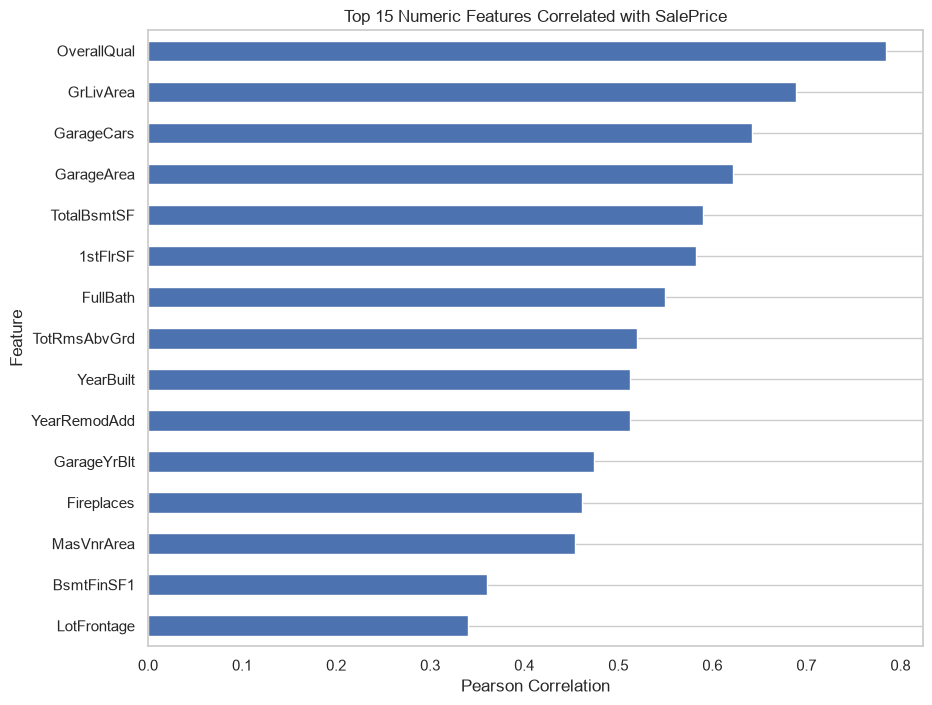

In [14]:
plt.figure(figsize=(10, 8))

target_correlation.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Numeric Features Correlated with SalePrice")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.grid(axis="x")
plt.show()

1.8. Аналіз мультиколінеарності
Мультиколінеарність — це ситуація, коли дві або більше незалежних змінних сильно корелюють між собою.

Обчислення кореляційної матриці

In [15]:
# Вибираємо числові ознаки тільки з Train
numeric_features = X_train.select_dtypes(include=np.number)

# Матриця кореляцій між ознаками
feature_corr = numeric_features.corr()

# Знаходимо пари ознак із кореляцією вище 0.8
upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper_triangle.stack()
    .reset_index()
)

high_corr_pairs.columns = ["Feature 1", "Feature 2", "Correlation"]

high_corr_pairs["Absolute Correlation"] = (
    high_corr_pairs["Correlation"].abs()
)

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Absolute Correlation"] > 0.8
].sort_values(
    by="Absolute Correlation",
    ascending=False
)

display(high_corr_pairs)

,Feature 1,Feature 2,Correlation,Absolute Correlation
926,GarageCars,GarageArea,0.881004,0.881004
408,TotalBsmtSF,1stFlrSF,0.826623,0.826623
562,GrLivArea,TotRmsAbvGrd,0.822992,0.822992
204,YearBuilt,GarageYrBlt,0.816767,0.816767


Візуалізація кореляцій

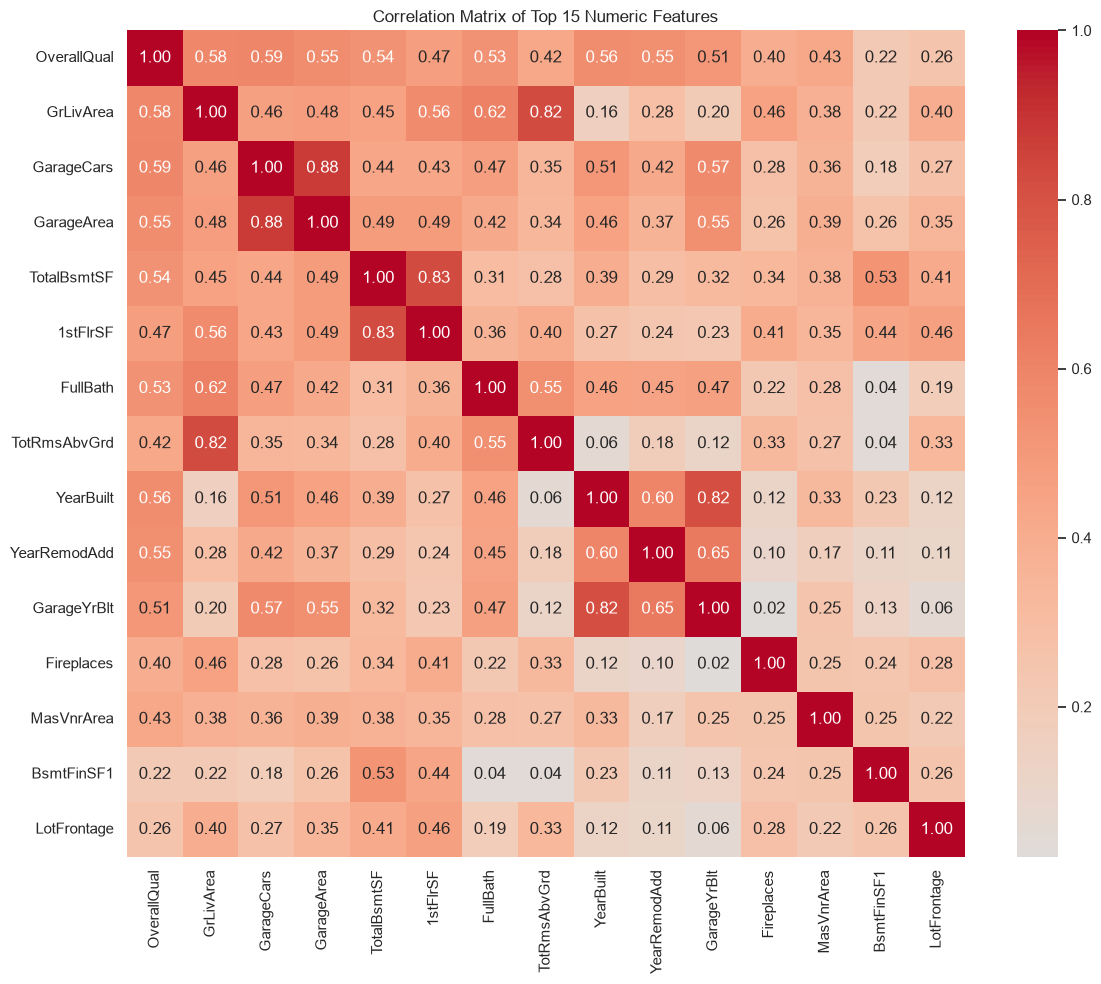

In [16]:
# Беремо 15 ознак із найсильнішим зв'язком із SalePrice
top_features = target_correlation.head(15).index.tolist()

# Матриця кореляцій між цими ознаками
plt.figure(figsize=(12, 10))

sns.heatmap(
    X_train[top_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Matrix of Top 15 Numeric Features")
plt.tight_layout()
plt.show()

### Висновок за результатами кореляційного аналізу

Проведений аналіз показав, що найбільший лінійний зв'язок із цільовою змінною SalePrice має ознака OverallQual (0.785). Також важливими характеристиками виявилися GrLivArea (0.689), GarageCars (0.643), GarageArea (0.622) та TotalBsmtSF (0.590).

Отримані результати свідчать, що якість будинку, його площа та характеристики гаража мають помітний зв'язок із вартістю нерухомості.

Однак для остаточного відбору ознак необхідно додатково дослідити мультиколінеарність, оскільки деякі незалежні змінні можуть містити схожу інформацію.

1.9. Додаткова перевірка мультиколінеарності — VIF
VIF (Variance Inflation Factor) показує, наскільки дисперсія оцінки коефіцієнта регресії збільшується через залежність конкретної ознаки від інших ознак.

In [17]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Беремо 15 числових ознак, які мають найсильніший зв'язок із SalePrice
vif_features = X_train[target_correlation.head(15).index].copy()

# Заповнюємо пропуски медіанами, обчисленими тільки на Train
vif_features = vif_features.fillna(vif_features.median())

# Додаємо константу
vif_features = add_constant(vif_features)

# Обчислюємо VIF
vif_table = pd.DataFrame({
    "Feature": vif_features.columns,
    "VIF": [
        variance_inflation_factor(vif_features.values, i)
        for i in range(vif_features.shape[1])
    ]
})

# Не враховуємо константу
vif_table = vif_table[vif_table["Feature"] != "const"]

vif_table = vif_table.sort_values(
    by="VIF",
    ascending=False
)

display(vif_table)

,Feature,VIF
2,GrLivArea,5.477888
4,GarageArea,5.319353
3,GarageCars,5.296187
5,TotalBsmtSF,4.156545
6,1stFlrSF,3.927480
9,YearBuilt,3.628589
8,TotRmsAbvGrd,3.453975
11,GarageYrBlt,3.049156
1,OverallQual,2.826494
7,FullBath,2.328356


### Висновок за результатами аналізу мультиколінеарності

За допомогою кореляційної матриці було виявлено чотири пари числових ознак із коефіцієнтом кореляції понад 0.8:

- GarageCars та GarageArea — 0.881.
- TotalBsmtSF та 1stFlrSF — 0.827.
- GrLivArea та TotRmsAbvGrd — 0.823.
- YearBuilt та GarageYrBlt — 0.817.

Це свідчить про наявність потенційної мультиколінеарності. Вона може призводити до нестабільності коефіцієнтів лінійної регресії та ускладнювати інтерпретацію впливу окремих ознак.

Для додаткової перевірки використовується показник VIF. Остаточне рішення щодо виключення ознак буде прийнято після оцінювання результатів цього показника.

### Висновок за результатами VIF

Для додаткової оцінки мультиколінеарності було розраховано показник VIF для 15 числових ознак із найсильнішим зв'язком із цільовою змінною.

Найбільші значення отримали GrLivArea (5.48), GarageArea (5.32) та GarageCars (5.30). Це свідчить про помірно підвищену мультиколінеарність цих характеристик.

Жодна ознака не перевищила поріг VIF = 10, тому критичної мультиколінеарності не виявлено. На цьому етапі вирішено залишити всі досліджувані ознаки, щоб не втрачати потенційно корисну інформацію для прогнозування ціни будинку.

1.12. Попередня обробка даних
Тепер переходимо до важливого етапу - підготовки даних для навчання лінійної регресії.

Визначення типів ознак


In [18]:
# Визначаємо числові та категоріальні ознаки
numeric_columns = X_train.select_dtypes(include=np.number).columns.tolist()

categorical_columns = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Кількість числових ознак:", len(numeric_columns))
print("Кількість категоріальних ознак:", len(categorical_columns))

print("\nЧислові ознаки:")
print(numeric_columns)

print("\nКатегоріальні ознаки:")
print(categorical_columns)

Кількість числових ознак: 36
Кількість категоріальних ознак: 43

Числові ознаки:
['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']

Категоріальні ознаки:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electri

C:\Users\YURII\AppData\Local\Temp\ipykernel_22172\1176877623.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


Обробка пропущених значень

In [19]:
# Копії вибірок, щоб не змінювати оригінальні дані
X_train_processed = X_train.copy()
X_val_processed = X_val.copy()
X_test_processed = X_test.copy()

# Ознаки, де пропуск означає відсутність об'єкта
none_columns = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual",
    "GarageCond", "PoolQC", "Fence", "MiscFeature",
    "MasVnrType"
]

for column in none_columns:
    if column in categorical_columns:
        X_train_processed[column] = X_train_processed[column].fillna("None")
        X_val_processed[column] = X_val_processed[column].fillna("None")
        X_test_processed[column] = X_test_processed[column].fillna("None")

print("Спеціальні категоріальні пропуски оброблено.")

Спеціальні категоріальні пропуски оброблено.


Імпутація числових і категоріальних ознак

In [20]:
from sklearn.impute import SimpleImputer

# Імпутер для числових ознак
numeric_imputer = SimpleImputer(strategy="median")

X_train_processed[numeric_columns] = numeric_imputer.fit_transform(
    X_train_processed[numeric_columns]
)

X_val_processed[numeric_columns] = numeric_imputer.transform(
    X_val_processed[numeric_columns]
)

X_test_processed[numeric_columns] = numeric_imputer.transform(
    X_test_processed[numeric_columns]
)

# Імпутер для категоріальних ознак
categorical_imputer = SimpleImputer(strategy="most_frequent")

X_train_processed[categorical_columns] = categorical_imputer.fit_transform(
    X_train_processed[categorical_columns]
)

X_val_processed[categorical_columns] = categorical_imputer.transform(
    X_val_processed[categorical_columns]
)

X_test_processed[categorical_columns] = categorical_imputer.transform(
    X_test_processed[categorical_columns]
)

print("Числові та категоріальні пропуски оброблено.")

Числові та категоріальні пропуски оброблено.


Перевірка пропусків


In [21]:
print("Пропуски у Train:", X_train_processed.isnull().sum().sum())
print("Пропуски у Validation:", X_val_processed.isnull().sum().sum())
print("Пропуски у Test:", X_test_processed.isnull().sum().sum())

Пропуски у Train: 0
Пропуски у Validation: 0
Пропуски у Test: 0


1.13. Кодування категоріальних ознак (One-Hot Encoding)

One-Hot Encoding
Для уникальних категорий створюватимуться окремі стовпці. Додамо drop="first", щоб уникнути надлишкової лінійної залежності між dummy-змінними.

In [22]:
from sklearn.preprocessing import OneHotEncoder

# Створюємо кодувальник
# handle_unknown="ignore" обробляє категорії,
# яких не було у Train, але які зустрілися у Validation або Test
encoder = OneHotEncoder(
    handle_unknown="ignore",
    drop="first",
    sparse_output=False
)

# Навчаємо кодувальник тільки на Train
X_train_encoded = encoder.fit_transform(
    X_train_processed[categorical_columns]
)

# Застосовуємо до інших вибірок
X_val_encoded = encoder.transform(
    X_val_processed[categorical_columns]
)

X_test_encoded = encoder.transform(
    X_test_processed[categorical_columns]
)

# Отримуємо назви нових ознак
encoded_columns = encoder.get_feature_names_out(categorical_columns)

print("Кількість категоріальних ознак після кодування:",
      len(encoded_columns))

Кількість категоріальних ознак після кодування: 218


d:\FELCT_4\ML\lab_1\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [10, 14] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
d:\FELCT_4\ML\lab_1\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [10, 15, 29] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Масштабування числових ознак
Використаємо StandardScaler, який перетворює числові ознаки так, щоб вони мали приблизно нульове середнє значення та одиничне стандартне відхилення.

In [23]:
from sklearn.preprocessing import StandardScaler

# Створюємо масштабувальник
scaler = StandardScaler()

# Навчаємо тільки на Train
X_train_scaled = scaler.fit_transform(
    X_train_processed[numeric_columns]
)

# Застосовуємо ті самі параметри до Validation і Test
X_val_scaled = scaler.transform(
    X_val_processed[numeric_columns]
)

X_test_scaled = scaler.transform(
    X_test_processed[numeric_columns]
)

print("Масштабування числових ознак завершено.")

Масштабування числових ознак завершено.


Об'єднання числових і категоріальних ознак
Тепер об'єднаємо результати кодування та масштабування в єдині таблиці.

In [24]:
# Створюємо DataFrame для числових ознак
X_train_numeric = pd.DataFrame(
    X_train_scaled,
    columns=numeric_columns,
    index=X_train.index
)

X_val_numeric = pd.DataFrame(
    X_val_scaled,
    columns=numeric_columns,
    index=X_val.index
)

X_test_numeric = pd.DataFrame(
    X_test_scaled,
    columns=numeric_columns,
    index=X_test.index
)

# Створюємо DataFrame для категоріальних ознак
X_train_categorical = pd.DataFrame(
    X_train_encoded,
    columns=encoded_columns,
    index=X_train.index
)

X_val_categorical = pd.DataFrame(
    X_val_encoded,
    columns=encoded_columns,
    index=X_val.index
)

X_test_categorical = pd.DataFrame(
    X_test_encoded,
    columns=encoded_columns,
    index=X_test.index
)

# Об'єднуємо всі ознаки
X_train_final = pd.concat(
    [X_train_numeric, X_train_categorical], axis=1
)

X_val_final = pd.concat(
    [X_val_numeric, X_val_categorical], axis=1
)

X_test_final = pd.concat(
    [X_test_numeric, X_test_categorical], axis=1
)

print("Train:", X_train_final.shape)
print("Validation:", X_val_final.shape)
print("Test:", X_test_final.shape)

Train: (1022, 254)
Validation: (219, 254)
Test: (219, 254)


Перевірка результатів

In [25]:
# Перевіряємо відсутність пропусків
print("Пропуски:")
print("Train:", X_train_final.isnull().sum().sum())
print("Validation:", X_val_final.isnull().sum().sum())
print("Test:", X_test_final.isnull().sum().sum())

# Перевіряємо масштабування числових ознак
print("\nСереднє значення першої числової ознаки:",
      X_train_final[numeric_columns[0]].mean())

print("Стандартне відхилення:",
      X_train_final[numeric_columns[0]].std())

# Переглядаємо результат
display(X_train_final.head())

Пропуски:
Train: 0
Validation: 0
Test: 0

Середнє значення першої числової ознаки: 2.4333655334250005e-17
Стандартне відхилення: 1.0004895961125637


,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,MSZoning_FV,MSZoning_RH,MSZoning_RL,MSZoning_RM,Street_Pave,Alley_None,Alley_Pave,LotShape_IR2,LotShape_IR3,LotShape_Reg,LandContour_HLS,LandContour_Low,LandContour_Lvl,Utilities_NoSeWa,LotConfig_CulDSac,LotConfig_FR2,LotConfig_FR3,LotConfig_Inside,LandSlope_Mod,LandSlope_Sev,Neighborhood_Blueste,Neighborhood_BrDale,Neighborhood_BrkSide,Neighborhood_ClearCr,Neighborhood_CollgCr,Neighborhood_Crawfor,Neighborhood_Edwards,Neighborhood_Gilbert,Neighborhood_IDOTRR,Neighborhood_MeadowV,Neighborhood_Mitchel,Neighborhood_NAmes,Neighborhood_NPkVill,Neighborhood_NWAmes,Neighborhood_NoRidge,Neighborhood_NridgHt,Neighborhood_OldTown,Neighborhood_SWISU,Neighborhood_Sawyer,Neighborhood_SawyerW,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber,Neighborhood_Veenker,Condition1_Feedr,Condition1_Norm,Condition1_PosA,Condition1_PosN,Condition1_RRAe,Condition1_RRAn,Condition1_RRNe,Condition1_RRNn,Condition2_Feedr,Condition2_Norm,Condition2_PosN,Condition2_RRAe,Condition2_RRAn,BldgType_2fmCon,BldgType_Duplex,BldgType_Twnhs,BldgType_TwnhsE,HouseStyle_1.5Unf,HouseStyle_1Story,HouseStyle_2.5Fin,HouseStyle_2.5Unf,HouseStyle_2Story,HouseStyle_SFoyer,HouseStyle_SLvl,RoofStyle_Gable,RoofStyle_Gambrel,RoofStyle_Hip,RoofStyle_Mansard,RoofStyle_Shed,RoofMatl_CompShg,RoofMatl_Metal,RoofMatl_Roll,RoofMatl_Tar&Grv,RoofMatl_WdShake,RoofMatl_WdShngl,Exterior1st_AsphShn,Exterior1st_BrkComm,Exterior1st_BrkFace,Exterior1st_CBlock,Exterior1st_CemntBd,Exterior1st_HdBoard,Exterior1st_MetalSd,Exterior1st_Plywood,Exterior1st_Stone,Exterior1st_Stucco,Exterior1st_VinylSd,Exterior1st_Wd Sdng,Exterior1st_WdShing,Exterior2nd_AsphShn,Exterior2nd_Brk Cmn,Exterior2nd_BrkFace,Exterior2nd_CBlock,Exterior2nd_CmentBd,Exterior2nd_HdBoard,Exterior2nd_ImStucc,Exterior2nd_MetalSd,Exterior2nd_Other,Exterior2nd_Plywood,Exterior2nd_Stone,Exterior2nd_Stucco,Exterior2nd_VinylSd,Exterior2nd_Wd Sdng,Exterior2nd_Wd Shng,MasVnrType_BrkFace,MasVnrType_None,MasVnrType_Stone,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,ExterCond_Fa,ExterCond_Gd,ExterCond_Po,ExterCond_TA,Foundation_CBlock,Foundation_PConc,Foundation_Slab,Foundation_Stone,Foundation_Wood,BsmtQual_Fa,BsmtQual_Gd,BsmtQual_None,BsmtQual_TA,BsmtCond_Gd,BsmtCond_None,BsmtCond_Po,BsmtCond_TA,BsmtExposure_Gd,BsmtExposure_Mn,BsmtExposure_No,BsmtExposure_None,BsmtFinType1_BLQ,BsmtFinType1_GLQ,BsmtFinType1_LwQ,BsmtFinType1_None,BsmtFinType1_Rec,BsmtFinType1_Unf,BsmtFinType2_BLQ,BsmtFinType2_GLQ,BsmtFinType2_LwQ,BsmtFinType2_None,BsmtFinType2_Rec,BsmtFinType2_Unf,Heating_GasA,Heating_GasW,Heating_Grav,Heating_OthW,Heating_Wall,HeatingQC_Fa,HeatingQC_Gd,HeatingQC_Po,HeatingQC_TA,CentralAir_Y,Electrical_FuseF,Electrical_FuseP,Electrical_SBrkr,KitchenQual_Fa,KitchenQual_Gd,KitchenQual_TA,Functional_Maj2,Functional_Min1,Functional_Min2,Functional_Mod,Functional_Sev,Functional_Typ,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA,GarageType_Attchd,GarageType_Basment,GarageType_BuiltIn,GarageType_CarPort,GarageType_Detchd,GarageType_None,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf,GarageQual_Fa,GarageQual_Gd,GarageQual_None,GarageQual_Po,GarageQual_TA,GarageCond_Fa,GarageCond_Gd,GarageCond_None,GarageCond_Po,GarageCond_TA,PavedDrive_P,PavedDrive_Y,PoolQC_Fa,PoolQC_Gd,PoolQC_None,Fence_GdWo,Fence_MnPrv,Fence_MnWw,Fence_None,MiscFeature_None,MiscFeature_Othr,MiscFeature_Shed,MiscFeature_TenC,SaleType_CWD,SaleType_Con,SaleType_ConLD,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
135,-0.868950,0.421055,

### Висновок щодо попередньої обробки даних

На цьому етапі було виконано підготовку даних для подальшого навчання моделі лінійної регресії.

1. Пропущені числові значення заповнено медіаною, категоріальні — найчастішим значенням або окремою категорією None, якщо пропуск означає відсутність об'єкта.
2. Категоріальні ознаки закодовано методом One-Hot Encoding.
3. Числові ознаки стандартизовано за допомогою StandardScaler.
4. Усі параметри попередньої обробки були визначені лише на навчальній вибірці Train.
5. До Validation і Test застосовано вже навчені перетворювачі.

Таким чином, отримано підготовлені числові матриці ознак, які можна використовувати для реалізації лінійної регресії засобами NumPy.

1.15. Фінальна перевірка підготовлених даних

In [26]:
print("Розміри фінальних матриць:")
print("Train:", X_train_final.shape)
print("Validation:", X_val_final.shape)
print("Test:", X_test_final.shape)

print("\nКількість ознак однакова:")
print(
    X_train_final.shape[1]
    == X_val_final.shape[1]
    == X_test_final.shape[1]
)

print("\nЧи всі значення скінченні:")
print("Train:", np.isfinite(X_train_final.to_numpy()).all())
print("Validation:", np.isfinite(X_val_final.to_numpy()).all())
print("Test:", np.isfinite(X_test_final.to_numpy()).all())

Розміри фінальних матриць:
Train: (1022, 254)
Validation: (219, 254)
Test: (219, 254)

Кількість ознак однакова:
True

Чи всі значення скінченні:
Train: True
Validation: True
Test: True


підготуємо дані у форматі NumPy для власної реалізації регресії:

In [27]:
# Перетворення матриць ознак у NumPy
X_train_np = X_train_final.to_numpy(dtype=np.float64)
X_val_np = X_val_final.to_numpy(dtype=np.float64)
X_test_np = X_test_final.to_numpy(dtype=np.float64)

# Перетворення цільової змінної
y_train_np = y_train.to_numpy(dtype=np.float64)
y_val_np = y_val.to_numpy(dtype=np.float64)
y_test_np = y_test.to_numpy(dtype=np.float64)

print("Формати даних:")
print("X_train:", X_train_np.shape)
print("y_train:", y_train_np.shape)

Формати даних:
X_train: (1022, 254)
y_train: (1022,)


In [28]:
# Параметри стандартизації цільової змінної
y_mean = y_train_np.mean()
y_std = y_train_np.std()

# Стандартизуємо цільові значення
y_train_scaled = (y_train_np - y_mean) / y_std
y_val_scaled = (y_val_np - y_mean) / y_std
y_test_scaled = (y_test_np - y_mean) / y_std

print("Середнє SalePrice:", y_mean)
print("Стандартне відхилення SalePrice:", y_std)

print("\nСереднє стандартизованого y_train:",
      y_train_scaled.mean())

print("Стандартне відхилення стандартизованого y_train:",
      y_train_scaled.std())

Середнє SalePrice: 181312.6927592955
Стандартне відхилення SalePrice: 77579.4783941699

Середнє стандартизованого y_train: 1.3557322257653574e-16
Стандартне відхилення стандартизованого y_train: 1.0


In [29]:
# Кількість ознак
n_features = X_train_np.shape[1]

# Початкові параметри
w = np.zeros(n_features)
b = 0.0

print("Кількість ваг:", len(w))
print("Початкове значення b:", b)

Кількість ваг: 254
Початкове значення b: 0.0


In [30]:
def predict(X, w, b):
    """
    Обчислює прогноз лінійної регресії.

    X - матриця ознак
    w - вектор ваг
    b - вільний член
    """
    y_pred = np.dot(X, w) + b

    return y_pred

In [31]:
y_pred = predict(X_train_np, w, b)

print("Розмір прогнозів:", y_pred.shape)
print("Перші 5 прогнозів:", y_pred[:5])

Розмір прогнозів: (1022,)
Перші 5 прогнозів: [0. 0. 0. 0. 0.]


In [32]:
def compute_mse(y_true, y_pred):
    """
    Обчислює середньоквадратичну помилку MSE.
    """
    m = len(y_true)

    mse = np.sum((y_pred - y_true) ** 2) / m

    return mse

In [33]:
initial_mse = compute_mse(y_train_scaled, y_pred)

print("Початкове значення MSE:", initial_mse)

Початкове значення MSE: 1.0


In [34]:
def compute_gradients(X, y_true, y_pred):
    """
    Обчислює градієнти за вагами та вільним членом.
    """
    m = len(y_true)

    error = y_pred - y_true

    # Градієнт за вагами
    dw = (2 / m) * np.dot(X.T, error)

    # Градієнт за вільним членом
    db = (2 / m) * np.sum(error)

    return dw, db

In [35]:
dw, db = compute_gradients(
    X_train_np,
    y_train_scaled,
    y_pred
)

print("Розмір градієнта ваг:", dw.shape)
print("Градієнт вільного члена:", db)
print("Перші 5 значень градієнта ваг:", dw[:5])

Розмір градієнта ваг: (254,)
Градієнт вільного члена: -2.711464451530715e-16
Перші 5 значень градієнта ваг: [ 0.18819736 -0.64084975 -0.52579266 -1.56943994  0.14292161]


In [36]:
def update_parameters(w, b, dw, db, learning_rate):
    """
    Оновлює ваги та вільний член моделі.
    """
    w_new = w - learning_rate * dw
    b_new = b - learning_rate * db

    return w_new, b_new

In [37]:
def train_batch_gd(X, y, learning_rate, epochs):
    # Ініціалізація параметрів
    n_features = X.shape[1]
    w = np.zeros(n_features)
    b = 0.0

    cost_history = []

    for epoch in range(epochs):
        # Прогнозування
        y_pred = predict(X, w, b)

        # Обчислення помилки
        cost = compute_mse(y, y_pred)
        cost_history.append(cost)

        # Обчислення градієнтів
        dw, db = compute_gradients(X, y, y_pred)

        # Оновлення параметрів
        w, b = update_parameters(
            w, b, dw, db, learning_rate
        )

    return w, b, cost_history

In [38]:
def train_sgd(X, y, learning_rate, epochs):
    n_samples, n_features = X.shape

    w = np.zeros(n_features)
    b = 0.0

    cost_history = []

    for epoch in range(epochs):
        # Випадкове перемішування індексів
        indices = np.random.permutation(n_samples)

        for i in indices:
            # Беремо один навчальний приклад
            X_i = X[i:i+1]
            y_i = y[i:i+1]

            # Прогноз
            y_pred = predict(X_i, w, b)

            # Градієнти
            dw, db = compute_gradients(X_i, y_i, y_pred)

            # Оновлення параметрів
            w, b = update_parameters(
                w, b, dw, db, learning_rate
            )

        # Після епохи обчислюємо MSE на всьому Train
        y_pred_all = predict(X, w, b)
        cost = compute_mse(y, y_pred_all)

        cost_history.append(cost)

    return w, b, cost_history

In [39]:
def train_minibatch_gd(X, y, learning_rate, epochs, batch_size):
    n_samples, n_features = X.shape

    w = np.zeros(n_features)
    b = 0.0

    cost_history = []

    for epoch in range(epochs):
        # Перемішуємо індекси
        indices = np.random.permutation(n_samples)

        # Перебираємо навчальні дані пакетами
        for start in range(0, n_samples, batch_size):
            end = start + batch_size

            batch_indices = indices[start:end]

            X_batch = X[batch_indices]
            y_batch = y[batch_indices]

            # Прогноз
            y_pred = predict(X_batch, w, b)

            # Градієнти
            dw, db = compute_gradients(
                X_batch, y_batch, y_pred
            )

            # Оновлення параметрів
            w, b = update_parameters(
                w, b, dw, db, learning_rate
            )

        # MSE на всьому Train після завершення епохи
        y_pred_all = predict(X, w, b)
        cost = compute_mse(y, y_pred_all)

        cost_history.append(cost)

    return w, b, cost_history

In [40]:
EPOCHS = 500
BATCH_SIZE = 32

# Для відтворюваності результатів SGD та Mini-batch
np.random.seed(42)

# Batch Gradient Descent
w_batch, b_batch, cost_batch = train_batch_gd(
    X_train_np,
    y_train_scaled,
    learning_rate=0.01,
    epochs=EPOCHS
)

# Stochastic Gradient Descent
w_sgd, b_sgd, cost_sgd = train_sgd(
    X_train_np,
    y_train_scaled,
    learning_rate=0.001,
    epochs=EPOCHS
)

# Mini-batch Gradient Descent
w_mini, b_mini, cost_mini = train_minibatch_gd(
    X_train_np,
    y_train_scaled,
    learning_rate=0.01,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE
)

print("Навчання завершено!")
print("Batch GD MSE:", cost_batch[-1])
print("SGD MSE:", cost_sgd[-1])
print("Mini-batch GD MSE:", cost_mini[-1])

Навчання завершено!
Batch GD MSE: 0.14078970857357187
SGD MSE: 0.08600775528401441
Mini-batch GD MSE: 0.09211122276202434


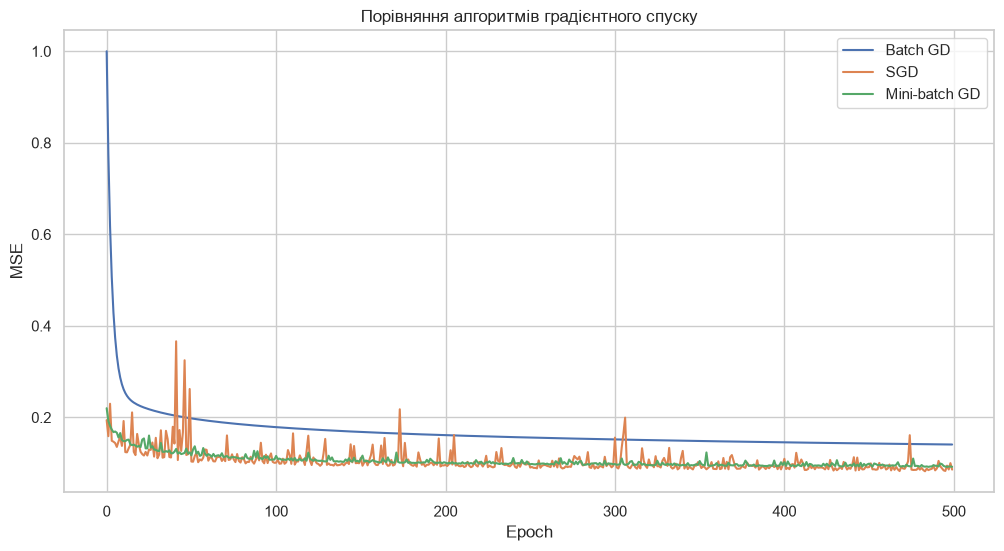

In [41]:
plt.figure(figsize=(12, 6))

plt.plot(cost_batch, label="Batch GD")
plt.plot(cost_sgd, label="SGD")
plt.plot(cost_mini, label="Mini-batch GD")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Порівняння алгоритмів градієнтного спуску")

plt.legend()
plt.grid(True)
plt.show()

### Аналіз результатів роботи алгоритмів градієнтного спуску

У результаті навчання було порівняно три алгоритми оптимізації: Batch Gradient Descent, Stochastic Gradient Descent та Mini-batch Gradient Descent.

Batch GD продемонстрував найбільш плавне та стабільне зменшення функції втрат. Це пояснюється тим, що градієнт обчислюється на основі всього навчального набору даних. Фінальне значення MSE становило 0.1408.

SGD характеризувався значними коливаннями функції втрат між епохами. Це пов'язано з оновленням параметрів після кожного окремого навчального прикладу. Незважаючи на нестабільність графіка, алгоритм досяг найменшого значення MSE — 0.0860.

Mini-batch GD також демонстрував коливання функції втрат, проте завдяки використанню груп із 32 прикладів забезпечував компроміс між стабільністю Batch GD та швидкістю оновлення параметрів SGD. Фінальна MSE становила 0.0921.

Отже, у проведеному експерименті найкращий результат за фінальною MSE показав SGD, а найбільш плавну збіжність продемонстрував Batch GD. Mini-batch GD забезпечив проміжний результат. Варто враховувати, що алгоритми виконують різну кількість оновлень параметрів протягом однієї епохи.

Коефіцієнт детермінації \(R^2\) показує, яку частку варіації цільової змінної пояснює модель. Значення, близьке до 1, свідчить про високу якість прогнозування. Від'ємне значення означає, що модель прогнозує гірше, ніж просте передбачення середнього значення цільової змінної.

In [42]:
def compute_r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)

    r2 = 1 - (ss_res / ss_tot)
    return r2

In [43]:
models = {
    "Batch GD": (w_batch, b_batch),
    "SGD": (w_sgd, b_sgd),
    "Mini-batch GD": (w_mini, b_mini)
}

for name, (w_model, b_model) in models.items():
    print(f"\n{name}")

    train_pred = predict(X_train_np, w_model, b_model)
    val_pred = predict(X_val_np, w_model, b_model)
    test_pred = predict(X_test_np, w_model, b_model)

    print("Train R²:", compute_r2(y_train_scaled, train_pred))
    print("Validation R²:", compute_r2(y_val_scaled, val_pred))
    print("Test R²:", compute_r2(y_test_scaled, test_pred))


Batch GD
Train R²: 0.8592527748958736
Validation R²: 0.9098951064401525
Test R²: 0.8288504025242966

SGD
Train R²: 0.9139922447159856
Validation R²: 0.8669326446984242
Test R²: 0.8748722832736929

Mini-batch GD
Train R²: 0.9078887772379757
Validation R²: 0.8743470748725602
Test R²: 0.865416962209354


### Оцінювання якості моделі за коефіцієнтом детермінації R²

Для оцінювання якості моделей було використано коефіцієнт детермінації R². Обчислення виконано окремо на навчальній, валідаційній та тестовій вибірках.

Усі три алгоритми показали достатньо високі значення R², що свідчить про здатність моделей пояснювати значну частину варіації цільової змінної SalePrice.

Batch GD отримав найвище значення R² на валідаційній вибірці — 0.9099. Водночас його результат на тестовій вибірці становив 0.8289.

SGD продемонстрував найвище значення R² на навчальній вибірці — 0.9140, а також найкращий результат на тестовій вибірці — 0.8749. Різниця між навчальним і тестовим результатами є відносно невеликою.

Mini-batch GD отримав R² = 0.9079 на навчальній вибірці та R² = 0.8654 на тестовій.

Отже, за результатами тестування найкращу здатність до узагальнення продемонстрував SGD. Водночас Batch GD показав найкращий результат на валідаційній вибірці. Значення R² залежать від складу вибірок, тому остаточне порівняння необхідно проводити з урахуванням усіх трьох показників.

Аналіз залишків моделі

Залишки — це різниця між справжніми та прогнозованими значеннями:
\[
e_i = y_i-\hat y_i
\]

Аналіз залишків дозволяє перевірити лінійність залежності, нормальність розподілу похибок та сталість їхньої дисперсії.

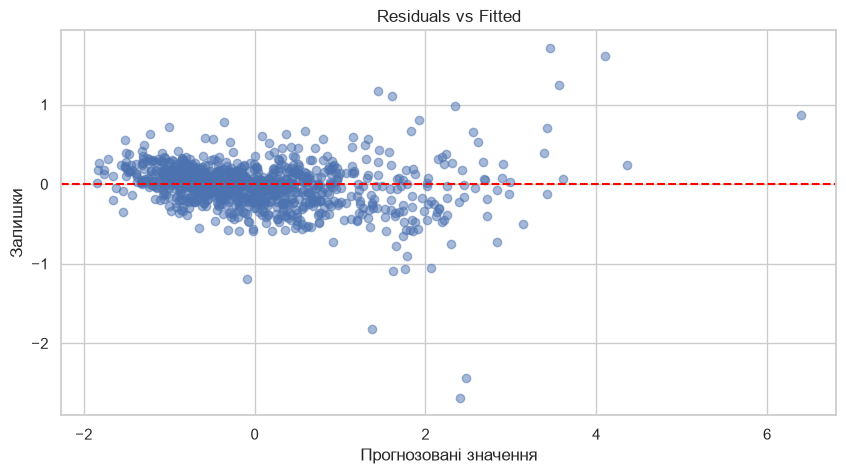

In [44]:
# Прогнозування на навчальній вибірці
y_pred_train = predict(X_train_np, w_sgd, b_sgd)

# Обчислення залишків
residuals = y_train_scaled - y_pred_train

# Побудова графіка залишків
plt.figure(figsize=(10, 5))
plt.scatter(y_pred_train, residuals, alpha=0.5)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Прогнозовані значення")
plt.ylabel("Залишки")
plt.title("Residuals vs Fitted")
plt.grid(True)
plt.show()

### Перевірка лінійності та гомоскедастичності

Для перевірки лінійності моделі було побудовано графік Residuals vs Fitted, який відображає залежність залишків від прогнозованих значень.

За результатами аналізу встановлено, що більшість залишків розташовані приблизно навколо горизонтальної лінії з нульовим значенням. Вираженої систематичної криволінійної залежності не спостерігається, тому припущення про лінійність загалом виконується.

Водночас зі збільшенням прогнозованих значень спостерігається зростання розкиду залишків. Це свідчить про можливе порушення припущення гомоскедастичності та наявність гетероскедастичності — неоднакової дисперсії похибок для різних рівнів прогнозованих значень.

Отже, модель загалом відображає лінійну залежність, проте припущення про сталість дисперсії залишків може не виконуватися.

Нормальність залишків (Normality of Residuals)

Припущення нормальності означає, що залишки моделі мають приблизно нормальний розподіл із середнім значенням, близьким до нуля. Для перевірки використовуються гістограма та Q-Q plot.

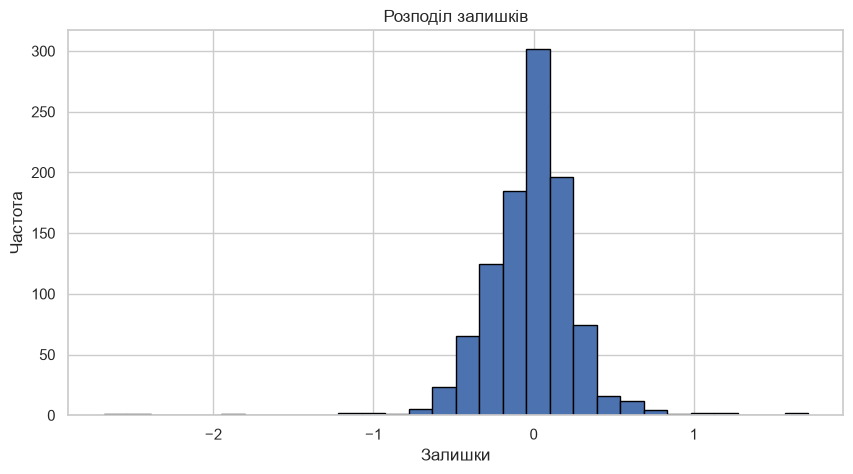

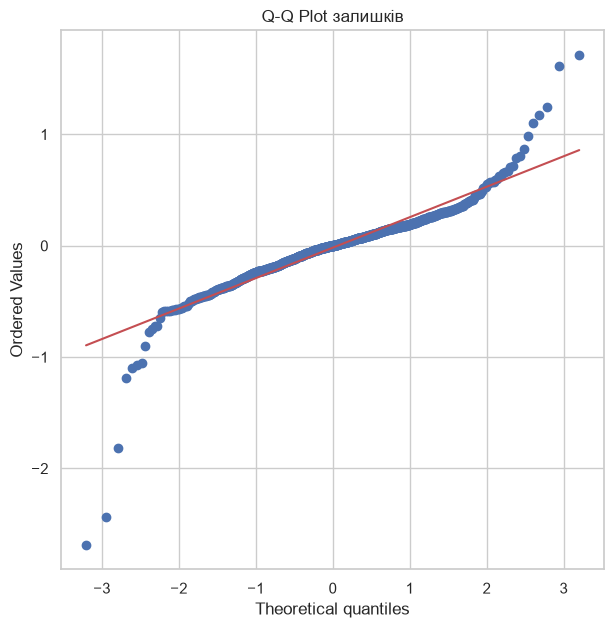

In [45]:
from scipy import stats

# Гістограма залишків
plt.figure(figsize=(10, 5))
plt.hist(residuals, bins=30, edgecolor="black")

plt.xlabel("Залишки")
plt.ylabel("Частота")
plt.title("Розподіл залишків")
plt.grid(True)
plt.show()

# Q-Q plot
plt.figure(figsize=(7, 7))
stats.probplot(residuals, dist="norm", plot=plt)

plt.title("Q-Q Plot залишків")
plt.grid(True)
plt.show()

In [46]:
shapiro_stat, shapiro_p = stats.shapiro(residuals)

print("Shapiro-Wilk statistic:", shapiro_stat)
print("P-value:", shapiro_p)

Shapiro-Wilk statistic: 0.8737220851026364
P-value: 5.802472847143125e-28


#### Перевірка нормальності залишків

Для перевірки нормальності розподілу залишків було використано гістограму, Q-Q plot та статистичний тест Шапіро — Вілка.

Гістограма показала найбільшу концентрацію залишків поблизу нуля з поступовим зменшенням частоти в обох напрямках.

На Q-Q plot більшість точок розташована поблизу теоретичної діагональної лінії, проте на кінцях спостерігаються значні відхилення. Це свідчить про можливу відмінність хвостів фактичного розподілу від нормального.

За результатами тесту Шапіро — Вілка отримано статистику W = 0.8737 та p-value = 5.80 × 10⁻²⁸. Оскільки p-value значно менше за рівень значущості 0.05, нульову гіпотезу про нормальність розподілу залишків відхилено.

Отже, припущення про нормальність залишків не виконується. Можливими причинами є наявність викидів та складна структура залежності вартості нерухомості від характеристик будинків.

#### Перевірка мультиколінеарності

Для оцінювання мультиколінеарності було використано кореляційну матрицю та показник VIF (Variance Inflation Factor).

Виявлено сильну кореляцію між окремими ознаками: GarageCars і GarageArea (0.881), TotalBsmtSF і 1stFlrSF (0.827), GrLivArea і TotRmsAbvGrd (0.823), YearBuilt і GarageYrBlt (0.817).

Найбільші значення VIF отримали GrLivArea (5.48), GarageArea (5.32) та GarageCars (5.30). Це свідчить про наявність потенційно суттєвої мультиколінеарності між деякими незалежними змінними.

Мультиколінеарність може призводити до нестабільності оцінок коефіцієнтів регресії та ускладнювати інтерпретацію впливу окремих ознак на цільову змінну.

Отже, припущення про відсутність мультиколінеарності повністю не виконується.

Stage 6. Експеримент C — L2-регуляризація (Ridge Regression)


2. Реалізація Ridge-регресії через NumPy

In [47]:
def compute_ridge_cost(y_true, y_pred, w, lambda_reg):
    m = len(y_true)

    mse = np.sum((y_pred - y_true) ** 2) / m
    regularization = (lambda_reg / (2 * m)) * np.sum(w ** 2)

    return mse + regularization

In [48]:
def compute_ridge_gradients(X, y_true, y_pred, w, lambda_reg):
    m = len(y_true)

    error = y_pred - y_true

    dw = (2 / m) * np.dot(X.T, error) + (lambda_reg / m) * w
    db = (2 / m) * np.sum(error)

    return dw, db


3. Навчання Ridge-моделі
Для експерименту використаємо Batch GD. Це дозволить порівняти звичайну лінійну регресію та Ridge за однаковим алгоритмом оптимізації.

In [49]:
def train_ridge(X, y, learning_rate, epochs, lambda_reg):
    n_samples, n_features = X.shape

    w = np.zeros(n_features)
    b = 0.0

    cost_history = []

    for epoch in range(epochs):
        y_pred = predict(X, w, b)

        cost = compute_ridge_cost(
            y, y_pred, w, lambda_reg
        )
        cost_history.append(cost)

        dw, db = compute_ridge_gradients(
            X, y, y_pred, w, lambda_reg
        )

        w, b = update_parameters(
            w, b, dw, db, learning_rate
        )

    return w, b, cost_history

In [50]:
lambda_values = [0, 10, 100, 1000]

ridge_models = {}

for lambda_reg in lambda_values:

    w_ridge, b_ridge, cost_history = train_ridge(
        X_train_np,
        y_train_scaled,
        learning_rate=0.01,
        epochs=500,
        lambda_reg=lambda_reg
    )

    ridge_models[lambda_reg] = (w_ridge, b_ridge)

    print(f"\nLambda = {lambda_reg}")
    print("Train R²:", compute_r2(
        y_train_scaled,
        predict(X_train_np, w_ridge, b_ridge)
    ))

    print("Validation R²:", compute_r2(
        y_val_scaled,
        predict(X_val_np, w_ridge, b_ridge)
    ))

    print("Weight norm:", np.linalg.norm(w_ridge))


Lambda = 0
Train R²: 0.8592527748958736
Validation R²: 0.9098951064401525
Weight norm: 0.6535976836220759

Lambda = 10
Train R²: 0.8585998574152172
Validation R²: 0.9099321104522429
Weight norm: 0.6448573724217788

Lambda = 100
Train R²: 0.8526475144267048
Validation R²: 0.9091483849372858
Weight norm: 0.577880646698239

Lambda = 1000
Train R²: 0.811621031403446
Validation R²: 0.8814275518264122
Weight norm: 0.3593026104271025


5. Візуалізація впливу регуляризації

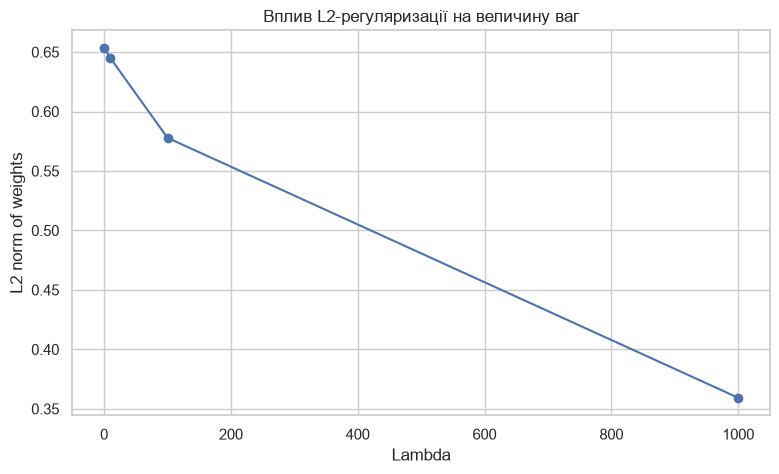

In [51]:
weight_norms = []

for lambda_reg in lambda_values:
    w_ridge, b_ridge = ridge_models[lambda_reg]
    weight_norms.append(np.linalg.norm(w_ridge))

plt.figure(figsize=(9, 5))

plt.plot(lambda_values, weight_norms, marker="o")

plt.xlabel("Lambda")
plt.ylabel("L2 norm of weights")
plt.title("Вплив L2-регуляризації на величину ваг")
plt.grid(True)

plt.show()

#### Аналіз впливу L2-регуляризації на якість моделі

Для дослідження впливу L2-регуляризації було перевірено чотири значення коефіцієнта λ: 0, 10, 100 та 1000.

При λ = 10 отримано найвище значення Validation R² — 0.90993, що практично не відрізняється від результату звичайної лінійної регресії без регуляризації (0.90990). Водночас норма ваг зменшилася з 0.6536 до 0.6449.

При λ = 100 значення Validation R² знизилося до 0.90915, а при λ = 1000 — до 0.88143. Значне зменшення норми ваг при λ = 1000 супроводжується погіршенням якості прогнозування, що свідчить про надмірну регуляризацію та можливе недонавчання моделі.

Отже, серед перевірених значень λ найкращий результат на валідаційній вибірці отримано при λ = 10. Однак покращення порівняно зі звичайною лінійною регресією є мінімальним. Експеримент підтверджує, що помірна регуляризація дозволяє зменшувати величину коефіцієнтів моделі без суттєвої втрати точності, тоді як надмірна регуляризація погіршує прогнозування.

In [52]:
# Отримуємо Ridge-модель з lambda = 10
w_ridge_10, b_ridge_10 = ridge_models[10]

# Прогнозування на тестовій вибірці
y_test_pred_ridge = predict(
    X_test_np, w_ridge_10, b_ridge_10
)

# R² для Ridge
ridge_test_r2 = compute_r2(
    y_test_scaled, y_test_pred_ridge
)

# R² для звичайної Batch GD
batch_test_r2 = compute_r2(
    y_test_scaled,
    predict(X_test_np, w_batch, b_batch)
)

print("Batch GD Test R²:", batch_test_r2)
print("Ridge (lambda=10) Test R²:", ridge_test_r2)

Batch GD Test R²: 0.8288504025242966
Ridge (lambda=10) Test R²: 0.8283182106905225


# Загальний висновок

У ході лабораторної роботи було досліджено методи побудови та оптимізації моделі лінійної регресії для прогнозування вартості житлової нерухомості на основі датасету Ames Housing.

На першому етапі проведено попередній аналіз даних, досліджено пропущені значення, розподіли ознак та кореляційні залежності. Виконано відбір і попередню обробку ознак, кодування категоріальних змінних, стандартизацію числових характеристик та поділ даних на навчальну, валідаційну й тестову вибірки.

На другому етапі реалізовано математичну модель лінійної регресії виключно засобами NumPy. Самостійно реалізовано функції прогнозування, обчислення середньоквадратичної похибки, градієнтів та оновлення параметрів моделі.

На третьому етапі реалізовано та порівняно три алгоритми оптимізації: Batch GD, SGD та Mini-batch GD. Найменшу фінальну MSE на навчальній вибірці отримав SGD (0.0860), тоді як Batch GD продемонстрував найбільш плавну збіжність.

На четвертому етапі проведено оцінювання моделей за допомогою коефіцієнта детермінації R². Найкращий результат на тестовій вибірці показав SGD (R² = 0.8749).

На п'ятому етапі досліджено статистичні припущення лінійної регресії. Виявлено, що припущення про лінійність загалом виконується, проте спостерігаються ознаки гетероскедастичності, відхилення залишків від нормального розподілу та мультиколінеарність між окремими ознаками.

На шостому етапі реалізовано Ridge-регресію з L2-регуляризацією. Досліджено вплив різних значень коефіцієнта λ на величину ваг та якість прогнозування. Встановлено, що регуляризація зменшує норму ваг, проте в проведеному експерименті не забезпечила суттєвого покращення результатів на тестовій вибірці.

У результаті роботи було отримано практичний досвід реалізації лінійної регресії та алгоритмів градієнтного спуску без використання готових інструментів машинного навчання. Також досліджено вплив регуляризації, особливості оцінювання якості моделі та важливість перевірки статистичних припущень регресійного аналізу.